In [1]:
import pandas as pd

df = pd.read_csv("../docs/resort_attributes.csv")
df

,resort,lat,lon,piste_km,lifts,base_alt,top_alt,vertical_drop,km_blue,km_red,km_black,snowmaking_share,family_friendly,freeride,parks,source_url,collected_on
0,Engelberg-Titlis,46.8162,8.3957,70,17,1003,3020,2017,18,42.5,9.5,0.4,1,1,0,https://www.skiresort.info/ski-resort/titlis-e...,2026-11-11


In [2]:
df.dtypes

resort               object
lat                 float64
lon                 float64
piste_km              int64
lifts                 int64
base_alt              int64
top_alt               int64
vertical_drop         int64
km_blue               int64
km_red              float64
km_black            float64
snowmaking_share    float64
family_friendly       int64
freeride              int64
parks                 int64
source_url           object
collected_on         object
dtype: object

In [4]:
# vertical drop = top - base?
print(df["vertical_drop"] == df["top_alt"] - df["base_alt"])

# blue + red + black km = total piste km?
print(df[["km_blue", "km_red", "km_black"]].sum(axis=1), df["piste_km"])

0    True
dtype: bool
0    70.0
dtype: float64 0    70
Name: piste_km, dtype: int64


## 8.2 Prices (Pricenow API)

### Step 3: test the request in the notebook

In [1]:
import json
import requests

URL = "https://api.pricenow.dev/api/booking/products/180000/journey/validities"

HEADERS = {
    "pratiq-channel-uuid": "dbe49cb5-8c06-498a-901c-fbf65d1166e5",
    "pratiq-api-version": "2025-02-18",
    "pratiq-superjson": "true",
    "accept-language": "en",
    "content-type": "application/json",
    "Origin": "https://shop.titlis.ch",
    "Referer": "https://shop.titlis.ch/",
    "User-Agent": "SkiGuru student project (UZH, non-commercial)",
}

form_state = {
    "allocation": {"kind": "persontype",
                   "values": [{"kind": "anonymous", "quantity": 1,
                               "personType": "adult_age20to999"}]},
    "attributes": {"duration": "1d"},
}

params = {
    "from": "2026-12-01T00:00:00.000+01:00",
    "to": "2026-12-31T23:59:59.999+01:00",
    "formState": json.dumps(form_state, separators=(",", ":")),
}

r = requests.get(URL, headers=HEADERS, params=params, timeout=20)
print(r.status_code)
print(r.text[:2000])

200
{"json":{"data":{"options":[{"availableCapacity":{"kind":"unlimited"},"value":{"from":"2026-11-30T23:00:00.000Z","to":"2026-12-01T22:59:59.999Z"},"label":"1 Tag und 1/2 Tag ab 12:00 Uhr","isAvailable":true,"price":{"minPrice":5400,"maxPrice":5400}},{"availableCapacity":{"kind":"unlimited"},"value":{"from":"2026-11-30T23:00:00.000Z","to":"2026-12-02T22:59:59.999Z"},"label":"2 Tage","isAvailable":true,"price":{"minPrice":10750,"maxPrice":10750}},{"availableCapacity":{"kind":"unlimited"},"value":{"from":"2026-11-30T23:00:00.000Z","to":"2026-12-03T22:59:59.999Z"},"label":"3 Tage","isAvailable":true,"price":{"minPrice":16100,"maxPrice":16100}},{"availableCapacity":{"kind":"unlimited"},"value":{"from":"2026-11-30T23:00:00.000Z","to":"2026-12-04T22:59:59.999Z"},"label":"4 Tage","isAvailable":true,"price":{"minPrice":20400,"maxPrice":20400}},{"availableCapacity":{"kind":"unlimited"},"value":{"from":"2026-11-30T23:00:00.000Z","to":"2026-12-05T22:59:59.999Z"},"label":"5 Tage","isAvailable":t

### Step 4: turn the response into a table and keep only day passes

In [2]:
import pandas as pd

options = r.json()["json"]["data"]["options"]
raw = pd.json_normalize(options)

# UTC → Swiss time
raw["start"] = pd.to_datetime(raw["value.from"]).dt.tz_convert("Europe/Zurich")
raw["end"] = pd.to_datetime(raw["value.to"]).dt.tz_convert("Europe/Zurich")

# number of days the ticket is valid
raw["n_days"] = (raw["end"].dt.normalize() - raw["start"].dt.normalize()).dt.days + 1

day = raw[raw["n_days"] == 1].copy()
day["date"] = day["start"].dt.date
day["price"] = day["price.minPrice"] / 100

print(raw.shape)
print(day["label"].unique())
day[["date", "price", "price.maxPrice", "isAvailable"]]

(434, 10)
['1 Tag und 1/2 Tag ab 12:00 Uhr']


,date,price,price.maxPrice,isAvailable
0,2026-12-01,54.0,5400,True
14,2026-12-02,53.5,5350,True
28,2026-12-03,53.5,5350,True
42,2026-12-04,53.5,5350,True
56,2026-12-05,61.0,6100,True
70,2026-12-06,61.5,6150,True
84,2026-12-07,53.5,5350,True
98,2026-12-08,56.0,5600,True
112,2026-12-09,53.0,5300,True
126,2026-12-10,53.5,5350,True


### Step 5: fetch all months of the season (Dec-Apr) in a loop

In [5]:
import time
from datetime import date

def fetch_month(year, month):
    """Day-pass prices (CHF) for one month at Engelberg-Titlis."""
    start = pd.Timestamp(year=year, month=month, day=1, tz="Europe/Zurich")
    end = start + pd.DateOffset(months=1) - pd.Timedelta(milliseconds=1)
    params = {
        "from": start.to_pydatetime().isoformat(timespec="milliseconds"),
        "to": end.to_pydatetime().isoformat(timespec="milliseconds"),
        "formState": json.dumps(form_state, separators=(",", ":")),
    }
    r = requests.get(URL, headers=HEADERS, params=params, timeout=20)
    r.raise_for_status()
    options = r.json()["json"]["data"]["options"]
    if not options:                      # e.g. after the end of the season
        return pd.DataFrame(columns=["date", "price"])

    raw = pd.json_normalize(options)
    raw["start"] = pd.to_datetime(raw["value.from"]).dt.tz_convert("Europe/Zurich")
    raw["end"] = pd.to_datetime(raw["value.to"]).dt.tz_convert("Europe/Zurich")
    raw["n_days"] = (raw["end"].dt.normalize() - raw["start"].dt.normalize()).dt.days + 1

    day = raw[raw["label"].str.startswith("1 Tag ") & raw["isAvailable"]].copy()
    day["date"] = day["start"].dt.date
    day["price"] = day["price.minPrice"] / 100
    return day[["date", "price"]]


months = [(2026, 12), (2027, 1), (2027, 2), (2027, 3), (2027, 4)]
frames = []
for y, m in months:
    frames.append(fetch_month(y, m))
    time.sleep(2)                        # pause between requests (politeness)

prices = pd.concat(frames, ignore_index=True)
prices["resort"] = "Engelberg-Titlis"
prices["scraped_on"] = date.today()
prices["days_ahead"] = (pd.to_datetime(prices["date"]) - pd.to_datetime(prices["scraped_on"])).dt.days
prices = prices[["resort", "date", "price", "scraped_on", "days_ahead"]]

print(prices.shape)
print(prices.groupby(pd.to_datetime(prices["date"]).dt.month)["price"].agg(["count", "min", "max"]))
prices.head()

(151, 5)
      count   min   max
date                   
1        31  54.5  67.5
2        28  62.5  68.5
3        31  54.0  65.5
4        30  51.0  59.0
12       31  53.0  69.0


,resort,date,price,scraped_on,days_ahead
0,Engelberg-Titlis,2026-12-01,54.0,2026-11-16,15
1,Engelberg-Titlis,2026-12-02,53.5,2026-11-16,16
2,Engelberg-Titlis,2026-12-03,53.5,2026-11-16,17
3,Engelberg-Titlis,2026-12-04,53.5,2026-11-16,18
4,Engelberg-Titlis,2026-12-05,61.0,2026-11-16,19


#### Step 5b: find duplicate and outlier

In [4]:
# 1. dates that appear more than once
print(prices[prices["date"].duplicated(keep=False)])

# 2. the five highest prices
print(prices.sort_values("price", ascending=False).head(5))

# 3. number of unique dates
print(prices["date"].nunique(), len(prices))

               resort        date  price  scraped_on  days_ahead
117  Engelberg-Titlis  2027-03-28   61.5  2026-11-16         132
118  Engelberg-Titlis  2027-03-28  120.5  2026-11-16         132
               resort        date  price  scraped_on  days_ahead
118  Engelberg-Titlis  2027-03-28  120.5  2026-11-16         132
28   Engelberg-Titlis  2026-12-29   69.0  2026-11-16          43
29   Engelberg-Titlis  2026-12-30   69.0  2026-11-16          44
30   Engelberg-Titlis  2026-12-31   69.0  2026-11-16          45
75   Engelberg-Titlis  2027-02-14   68.5  2026-11-16          90
151 152


## 8.3 Train (transport.opendata.ch)

In [6]:
url = "https://transport.opendata.ch/v1/connections"
params = {"from": "Zürich HB", "to": "Engelberg", "date": "2026-12-10", "time": "07:00", "limit": 4}

r = requests.get(url, params=params, timeout=20)
print(r.status_code)

for c in r.json()["connections"]:
    print(c["from"]["departure"], "→", c["to"]["arrival"], "| duration:", c["duration"], "| changes:", c["transfers"])

200
2026-12-10T07:10:00+0100 → 2026-12-10T08:53:00+0100 | duration: 00d01:43:00 | changes: 1
2026-12-10T08:10:00+0100 → 2026-12-10T09:53:00+0100 | duration: 00d01:43:00 | changes: 1
2026-12-10T09:10:00+0100 → 2026-12-10T10:53:00+0100 | duration: 00d01:43:00 | changes: 1
2026-12-10T10:10:00+0100 → 2026-12-10T11:53:00+0100 | duration: 00d01:43:00 | changes: 1


In [7]:
def parse_duration(s):
    """'00d01:43:00' → 103 (minutes)"""
    days, hms = s.split("d")
    h, m, _ = map(int, hms.split(":"))
    return int(days) * 24 * 60 + h * 60 + m


def train_minutes(frm, to, date, time_):
    """Shortest of the next 4 connections, in minutes."""
    params = {"from": frm, "to": to, "date": date, "time": time_, "limit": 4}
    r = requests.get(url, params=params, timeout=20)
    r.raise_for_status()
    return min(parse_duration(c["duration"]) for c in r.json()["connections"])


WALK = 10  # Engelberg station → Titlis valley station, minutes (each way)

t_out = train_minutes("Zürich HB", "Engelberg", "2026-12-10", "07:00")
time.sleep(1)
t_back = train_minutes("Engelberg", "Zürich HB", "2026-12-10", "16:30")

T = t_out + t_back + 2 * WALK
print(f"out {t_out} min, back {t_back} min, total {T} min = {T/60:.2f} h")

out 103 min, back 109 min, total 232 min = 3.87 h


### Compute travel cost K by pass type

In [8]:
fares = pd.read_csv("../docs/train_fares.csv")
fare = fares.loc[fares["resort"] == "Engelberg-Titlis"].iloc[0]

def train_cost(fare, travel_pass):
    """Return fare in CHF for 'none', 'Halbtax' or 'GA'."""
    if travel_pass == "GA":
        return 0.0
    if travel_pass == "Halbtax":
        return fare["fare_halbtax_return"]
    return fare["fare_full_return"]

v = 20  # example value of time, CHF per hour

for p in ["none", "Halbtax", "GA"]:
    K = train_cost(fare, p)
    print(f"{p:8}  K = {K:5.2f}   v·T = {v * T / 60:5.2f}   K + v·T = {K + v * T / 60:6.2f}")

none      K = 80.00   v·T = 77.33   K + v·T = 157.33
Halbtax   K = 40.00   v·T = 77.33   K + v·T = 117.33
GA        K =  0.00   v·T = 77.33   K + v·T =  77.33


## 8.4 Car (OpenRouteService)

In [9]:
from pathlib import Path

def read_env(path="../.env"):
    """Read KEY=value lines from .env (without printing them)."""
    env = {}
    for line in Path(path).read_text().splitlines():
        if "=" in line and not line.startswith("#"):
            k, v = line.split("=", 1)
            env[k.strip()] = v.strip()
    return env

ORS_KEY = read_env()["ORS_KEY"]
ORS_URL = "https://api.heigit.org/openrouteservice/v2/directions/driving-car"

ZURICH_HB = [8.5403, 47.3779]                       # [lon, lat]
resort = pd.read_csv("../docs/resort_attributes.csv").iloc[0]
ENGELBERG = [resort["lon"], resort["lat"]]          # Titlis valley station

def drive(start, end):
    """One-way car route → (km, minutes)."""
    r = requests.post(ORS_URL,
                      headers={"Authorization": ORS_KEY, "Content-Type": "application/json"},
                      json={"coordinates": [start, end]},
                      timeout=30)
    r.raise_for_status()
    s = r.json()["routes"][0]["summary"]
    return s["distance"] / 1000, s["duration"] / 60

km_out, min_out = drive(ZURICH_HB, ENGELBERG)
time.sleep(2)
km_back, min_back = drive(ENGELBERG, ZURICH_HB)
print(f"out {km_out:.1f} km, {min_out:.0f} min | back {km_back:.1f} km, {min_back:.0f} min")

out 85.5 km, 76 min | back 86.4 km, 79 min


### Compute the car's K and T

In [10]:
COST_PER_KM = 4135 / 15000   # TCS 2026: variable costs per year / 15,000 km ≈ 0.28 CHF/km

parking = pd.read_csv("../docs/car_parking.csv")
park = parking.loc[parking["resort"] == "Engelberg-Titlis", "parking_chf_day"].iloc[0]

km_round = km_out + km_back
T_car = min_out + min_back           # car parks at the valley station → no walk
K_car = COST_PER_KM * km_round + park

print(f"cost per km: {COST_PER_KM:.4f} CHF")
print(f"car:             {km_round:.1f} km   K = {K_car:6.2f}   T = {T_car:3.0f} min   K + v·T = {K_car + v * T_car / 60:6.2f}")
print(f"train (Halbtax):              K = {40:6.2f}   T = {T:3.0f} min   K + v·T = {40 + v * T / 60:6.2f}")
print(f"train (full):                 K = {80:6.2f}   T = {T:3.0f} min   K + v·T = {80 + v * T / 60:6.2f}")

cost per km: 0.2757 CHF
car:             171.9 km   K =  57.39   T = 155 min   K + v·T = 109.11
train (Halbtax):              K =  40.00   T = 232 min   K + v·T = 117.33
train (full):                 K =  80.00   T = 232 min   K + v·T = 157.33


## 8.5 Snow

In [11]:
import numpy as np

stations = pd.read_csv("../data_clean/stationen.csv")
stations = stations[stations["typ"] == "schnee"].copy()

def haversine_km(lat1, lon1, lat2, lon2):
    """Straight-line distance between two points on Earth, in km."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

stations["dist_km"] = haversine_km(resort["lat"], resort["lon"], stations["lat"], stations["lon"])
stations["alt_diff_m"] = stations["hoehe"] - resort["base_alt"]

stations.sort_values("dist_km").head(5)[["station_code", "name", "hoehe", "messbeginn", "dist_km", "alt_diff_m"]]

,station_code,name,hoehe,messbeginn,dist_km,alt_diff_m
180,TIT2,Titlisboden,2149.0,1993,3.517132,1146.0
75,GAD2,Gschletteregg,2063.0,1998,8.008424,1060.0
121,MEI2,Laucheren,2220.0,1997,14.308655,1217.0
89,GUT2,Homad,2115.0,1999,17.231736,1112.0
163,SCB2,Schönbüel,1777.0,2000,22.621036,774.0


### Load the TIT2 snow data and compute the historical average

In [12]:
snow = pd.read_parquet("../data_clean/daily_snow.parquet")
snow["station_code"] = snow["station_code"].astype(str)

tit = snow[snow["station_code"] == "TIT2"].copy()
tit["datum"] = pd.to_datetime(tit["datum"])

print("data from", tit["datum"].min().date(), "to", tit["datum"].max().date(), "|", len(tit), "days")
print(tit.tail(5)[["datum", "HS", "HN_1D"]])

# fallback: median snow depth per calendar day over all past winters
tit["day"] = tit["datum"].dt.strftime("%m-%d")
clim = tit.groupby("day")["HS"].agg(["median", "count"])

for d in ["12-01", "12-25", "01-15", "02-15", "03-15", "04-15"]:
    print(d, "median HS:", clim.loc[d, "median"], "cm   (winters:", clim.loc[d, "count"], ")")

data from 1993-06-01 to 2026-11-08 | 12144 days
             datum   HS  HN_1D
1219701 2026-11-04  1.0    0.0
1219833 2026-11-05  0.0    0.0
1219965 2026-11-06  1.0    0.0
1220097 2026-11-07  1.0    4.4
1220229 2026-11-08  2.0    0.0
12-01 median HS: 40.0 cm   (winters: 33 )
12-25 median HS: 86.0 cm   (winters: 33 )
01-15 median HS: 117.0 cm   (winters: 33 )
02-15 median HS: 161.0 cm   (winters: 33 )
03-15 median HS: 219.5 cm   (winters: 32 )
04-15 median HS: 224.0 cm   (winters: 32 )


### Expected snow per date, with caps

In [13]:
HS_CAP = 150   # cm snow depth → score 1
HN_CAP = 30    # cm new snow in 3 days → score 1

# new snow over the last 3 days (time-based, robust to missing days)
tit = tit.sort_values("datum")
tit["HN_3D"] = tit.set_index("datum")["HN_1D"].rolling("3D").sum().values

clim = tit.groupby("day").agg(HS_median=("HS", "median"),
                              HN3_mean=("HN_3D", "mean"),
                              winters=("HS", "count"))

def expected_snow(date):
    """Fallback until Dimi's regression exists: historical values for this calendar day."""
    row = clim.loc[pd.Timestamp(date).strftime("%m-%d")]
    hs, hn3 = row["HS_median"], row["HN3_mean"]
    return {"HS_exp": hs,
            "HN3_exp": round(hn3, 1),
            "x_snow_depth": round(min(hs / HS_CAP, 1), 2),
            "x_new_snow": round(min(hn3 / HN_CAP, 1), 2)}

for d in ["2026-12-01", "2026-12-25", "2027-01-15", "2027-02-15", "2027-03-15", "2027-04-15"]:
    print(d, expected_snow(d))

2026-12-01 {'HS_exp': np.float64(40.0), 'HN3_exp': np.float64(27.9), 'x_snow_depth': np.float64(0.27), 'x_new_snow': np.float64(0.93)}
2026-12-25 {'HS_exp': np.float64(86.0), 'HN3_exp': np.float64(32.5), 'x_snow_depth': np.float64(0.57), 'x_new_snow': 1}
2027-01-15 {'HS_exp': np.float64(117.0), 'HN3_exp': np.float64(38.7), 'x_snow_depth': np.float64(0.78), 'x_new_snow': 1}
2027-02-15 {'HS_exp': np.float64(161.0), 'HN3_exp': np.float64(18.6), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.62)}
2027-03-15 {'HS_exp': np.float64(219.5), 'HN3_exp': np.float64(25.2), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.84)}
2027-04-15 {'HS_exp': np.float64(224.0), 'HN3_exp': np.float64(22.9), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.76)}


### Check the new-snow data

In [14]:
w = tit[tit["datum"].dt.month.isin([12, 1, 2, 3])]

print("winter days:", len(w))
print("HN_1D missing (NaN):", w["HN_1D"].isna().sum())
print("HN_1D = 0:", (w["HN_1D"] == 0).sum())
print("HN_1D > 0:", (w["HN_1D"] > 0).sum())
print("mean HN_1D (NaN ignored):", round(w["HN_1D"].mean(), 1))
print("mean HN_1D (NaN = 0):", round(w["HN_1D"].fillna(0).mean(), 1))
print(w["HN_1D"].describe())

winter days: 3995
HN_1D missing (NaN): 2176
HN_1D = 0: 1031
HN_1D > 0: 788
mean HN_1D (NaN ignored): 8.1
mean HN_1D (NaN = 0): 3.7
count    1819.000000
mean        8.134853
std        16.723490
min         0.000000
25%         0.000000
50%         0.000000
75%         9.900000
max       234.399994
Name: HN_1D, dtype: float64


### Clean up the new-snow calculation

In [15]:
# 1. more than 100 cm in one day = measurement error → treat as missing
tit["HN_clean"] = tit["HN_1D"].where(tit["HN_1D"] <= 100)
print("first day with new-snow data:", tit.loc[tit["HN_clean"].notna(), "datum"].min().date())

# 2. mean daily new snow per calendar day, only over measured days
daily_hn = tit.groupby("day")["HN_clean"].mean()

# 3. smooth over ±7 days (wraps around New Year), then × 3 for 3 days
ext = pd.concat([daily_hn.iloc[-7:], daily_hn, daily_hn.iloc[:7]])
smooth = ext.rolling(15, center=True).mean().iloc[7:-7]
clim["HN3_mean"] = 3 * smooth

for d in ["2026-12-01", "2026-12-25", "2027-01-15", "2027-02-15", "2027-03-15", "2027-04-15"]:
    print(d, expected_snow(d))

first day with new-snow data: 2011-09-16
2026-12-01 {'HS_exp': np.float64(40.0), 'HN3_exp': np.float64(20.1), 'x_snow_depth': np.float64(0.27), 'x_new_snow': np.float64(0.67)}
2026-12-25 {'HS_exp': np.float64(86.0), 'HN3_exp': np.float64(21.5), 'x_snow_depth': np.float64(0.57), 'x_new_snow': np.float64(0.72)}
2027-01-15 {'HS_exp': np.float64(117.0), 'HN3_exp': np.float64(30.0), 'x_snow_depth': np.float64(0.78), 'x_new_snow': np.float64(1.0)}
2027-02-15 {'HS_exp': np.float64(161.0), 'HN3_exp': np.float64(21.3), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.71)}
2027-03-15 {'HS_exp': np.float64(219.5), 'HN3_exp': np.float64(16.7), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.56)}
2027-04-15 {'HS_exp': np.float64(224.0), 'HN3_exp': np.float64(19.0), 'x_snow_depth': 1, 'x_new_snow': np.float64(0.63)}


### Check gaps after 2011

In [16]:
since = tit[(tit["datum"] >= "2011-10-01") & tit["datum"].dt.month.isin([12, 1, 2, 3])]

print("winter days since 2011:", len(since))
print("share missing:", round(since["HN_clean"].isna().mean(), 2))
print("mean HN (NaN ignored):", round(since["HN_clean"].mean(), 1))
print("mean HN (NaN = 0):", round(since["HN_clean"].fillna(0).mean(), 1))

winter days since 2011: 1819
share missing: 0.0
mean HN (NaN ignored): 7.6
mean HN (NaN = 0): 7.6


## 8.6 Consumer surplus

In [17]:
attrs = pd.read_csv("../docs/resort_attributes.csv").iloc[0]
prices = pd.read_csv("../data_clean/prices.csv")
snow_exp = pd.read_csv("../data_clean/snow_expected.csv")
train = pd.read_csv("../data_clean/travel_train.csv").iloc[0]
car = pd.read_csv("../data_clean/travel_car.csv").iloc[0]

RANGES = {"piste_km": (0, 300), "lifts": (0, 80), "vertical_drop": (0, 2200),
          "top_alt": (1500, 3500), "snowmaking_share": (0, 1),
          "family_friendly": (0, 1), "freeride": (0, 1), "parks": (0, 1)}
WEIGHTS = {"piste_km": 30, "lifts": 5, "vertical_drop": 15, "top_alt": 10,
           "snowmaking_share": 5, "x_snow_depth": 25, "x_new_snow": 10,
           "family_friendly": 5, "freeride": 5, "parks": 5}

def scale(x, lo, hi):
    """Scale to 0–1 with a fixed range, clipped at 0 and 1."""
    return min(max((x - lo) / (hi - lo), 0), 1)

def consumer_surplus(date, B0=150, v=20, mode="train", travel_pass="Halbtax"):
    x = {k: scale(attrs[k], *RANGES[k]) for k in RANGES}
    s = snow_exp.loc[snow_exp["date"] == date].iloc[0]
    x["x_snow_depth"], x["x_new_snow"] = s["x_snow_depth"], s["x_new_snow"]

    B = B0 + sum(WEIGHTS[k] * x[k] for k in WEIGHTS)
    P = prices.loc[prices["date"] == date, "price"].iloc[-1]   # latest scrape
    if mode == "car":
        K, T = car["k_car"], car["t_round_min"] / 60
    else:
        K = {"none": train["fare_full_return"],
             "Halbtax": train["fare_halbtax_return"], "GA": 0.0}[travel_pass]
        T = train["t_round_min"] / 60
    return {"B": round(B, 2), "P": P, "K": K, "v·T": round(v * T, 2),
            "CS": round(B - P - K - v * T, 2)}

for mode, tp in [("train", "none"), ("train", "Halbtax"), ("train", "GA"), ("car", None)]:
    print(f"{mode:5} {str(tp):8}", consumer_surplus("2027-01-15", mode=mode, travel_pass=tp))

train none     {'B': np.float64(220.91), 'P': np.float64(58.0), 'K': np.float64(80.0), 'v·T': np.float64(77.33), 'CS': np.float64(5.58)}
train Halbtax  {'B': np.float64(220.91), 'P': np.float64(58.0), 'K': np.float64(40.0), 'v·T': np.float64(77.33), 'CS': np.float64(45.58)}
train GA       {'B': np.float64(220.91), 'P': np.float64(58.0), 'K': 0.0, 'v·T': np.float64(77.33), 'CS': np.float64(85.58)}
car   None     {'B': np.float64(220.91), 'P': np.float64(58.0), 'K': np.float64(57.39), 'v·T': np.float64(51.67), 'CS': np.float64(53.86)}


### CS for every day of the season

            P       B      CS
count  151.00  151.00  151.00
mean    59.70  219.89   42.86
std      5.11    5.77    7.67
min     51.00  204.56   26.33
25%     55.50  216.18   36.83
50%     60.50  222.41   44.08
75%     64.00  223.51   48.13
max     69.00  226.41   55.78

best 5 days:
           date     P       B     CS
141 2027-04-21  51.0  224.11  55.78
142 2027-04-22  51.0  224.11  55.78
143 2027-04-23  51.0  224.01  55.68
140 2027-04-20  51.0  223.71  55.38
139 2027-04-19  51.0  223.21  54.88

worst 5 days:
          date     P       B     CS
4  2026-12-05  61.0  204.66  26.33
5  2026-12-06  61.5  206.51  27.68
30 2026-12-31  69.0  214.31  27.98
28 2026-12-29  69.0  214.76  28.43
27 2026-12-28  68.0  214.16  28.83


<Axes: title={'center': 'Engelberg-Titlis: price and CS (train, Halbtax)'}, xlabel='date'>

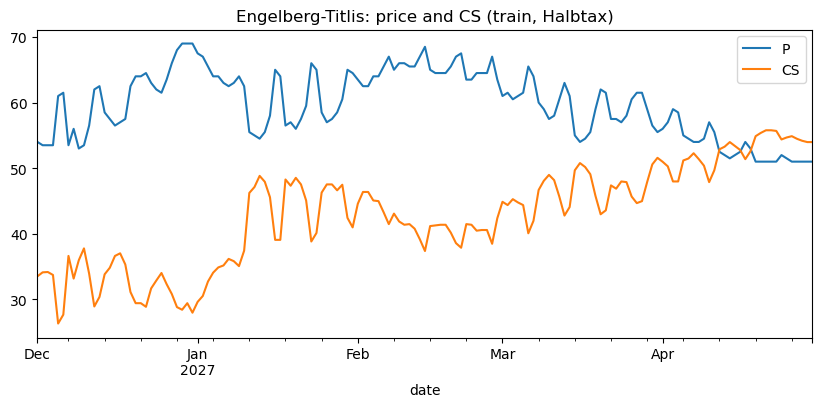

In [18]:
dates = prices["date"].unique()
season = pd.DataFrame([{"date": d, **consumer_surplus(d)} for d in dates])   # train, Halbtax, B0=150, v=20
season["date"] = pd.to_datetime(season["date"])

print(season[["P", "B", "CS"]].describe().round(2))
print("\nbest 5 days:\n", season.nlargest(5, "CS")[["date", "P", "B", "CS"]])
print("\nworst 5 days:\n", season.nsmallest(5, "CS")[["date", "P", "B", "CS"]])

season.set_index("date")[["P", "CS"]].plot(figsize=(10, 4), title="Engelberg-Titlis: price and CS (train, Halbtax)")

### Test finde.py

In [19]:
import sys
sys.path.append("..")
from src.finder import load_data, consumer_surplus

data = load_data()
print(consumer_surplus(data, "Engelberg-Titlis", "2027-01-15"))
print(consumer_surplus(data, "Engelberg-Titlis", "2027-01-15", mode="car"))

{'resort': 'Engelberg-Titlis', 'date': '2027-01-15', 'B': np.float64(220.91), 'P': 58.0, 'K': 40.0, 'T_h': np.float64(3.87), 'vT': np.float64(77.33), 'CS': np.float64(45.58)}
{'resort': 'Engelberg-Titlis', 'date': '2027-01-15', 'B': np.float64(220.91), 'P': 58.0, 'K': 57.39, 'T_h': np.float64(2.58), 'vT': np.float64(51.67), 'CS': np.float64(53.86)}
